# Lesson 0: start here, what MBQC is

This notebook is for readers who know what a qubit, a quantum gate and a measurement are, but have not met measurement-based quantum computation (MBQC). It answers one question with small runnable examples: **can a quantum computer run with no gates at all during the computation, only single-qubit measurements?** Surprisingly, yes, as long as it starts from the right entangled state. The six numbered lessons then build the full picture.

Background portals: [one-way quantum computer](https://en.wikipedia.org/wiki/One-way_quantum_computer), [cluster state](https://en.wikipedia.org/wiki/Cluster_state), [Bloch sphere](https://en.wikipedia.org/wiki/Bloch_sphere). A tutorial introduction: Browne and Briegel, [arXiv:quant-ph/0603226](https://arxiv.org/abs/quant-ph/0603226).

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from mbqc import *

rng = np.random.default_rng(2026)

## The idea

In the usual circuit model, a computation is a sequence of gates applied to qubits, followed by measurements at the end. MBQC ([Raussendorf and Briegel, arXiv:quant-ph/0010033](https://arxiv.org/abs/quant-ph/0010033)) reorganizes this:

1. **Make a large entangled resource state once**, always the same one, independent of the problem. The standard choice is a *cluster state*: qubits on a grid, each prepared in $|+\rangle$, with a controlled-Z (CZ) gate applied across every edge.
2. **Compute by measuring qubits one at a time**, each in a basis of your choice. The program is the list of measurement angles.
3. **Adapt**: measurement outcomes are random, so later angles depend on earlier outcomes (*feedforward*).

The entanglement is the fuel and the measurements burn it. Why bother? For photons, two-qubit gates between flying qubits are very hard, but making small entangled states, interfering them and measuring is natural. Photonic quantum computers, such as Xanadu's design ([Bourassa et al., arXiv:2010.02905](https://arxiv.org/abs/2010.02905)), are measurement-based for that reason. Here is a small cluster state, drawn as its graph:

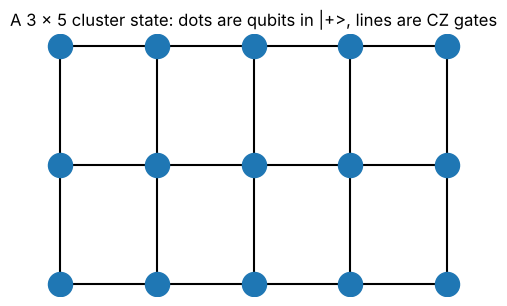

In [2]:
rows, cols = 3, 5
edges = grid_edges(rows, cols)
plt.figure(figsize=(5.5, 3.4))
for (r1, c1), (r2, c2) in edges:
    plt.plot([c1, c2], [r1, r2], "k-", lw=1.5, zorder=1)
plt.scatter([c for r in range(rows) for c in range(cols)], [r for r in range(rows) for c in range(cols)],
            s=300, color="C0", zorder=2)
plt.axis("off")
plt.title("A 3 x 5 cluster state: dots are qubits in |+>, lines are CZ gates");

## The basic move: one measurement teleports and rotates a qubit

Take just two qubits. Put an arbitrary state $|\psi\rangle$ on qubit 1, $|+\rangle$ on qubit 2, apply one CZ, then measure qubit 1 in the basis $|\pm_\theta\rangle = (|0\rangle \pm e^{i\theta}|1\rangle)/\sqrt2$, which lies on the equator of the Bloch sphere at angle $\theta$. Qubit 1 is gone, and qubit 2 now holds

$$X^s\, J(\theta)\, |\psi\rangle, \qquad J(\theta) = H\,P(-\theta) = \tfrac{1}{\sqrt2}\begin{pmatrix} 1 & e^{-i\theta} \\ 1 & -e^{-i\theta}\end{pmatrix},$$

where $s \in \{0, 1\}$ is the random outcome. So the state **moved** to qubit 2 and was **rotated** by a gate we chose through $\theta$. The only blemish is the extra $X$ when $s = 1$, a known "byproduct" that we can undo, or simply keep track of. Let's check this for every $\theta$:

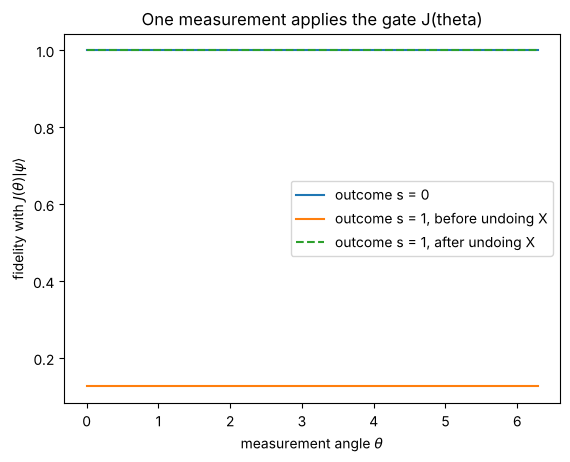

In [3]:
psi = random_state(1, rng)
thetas = np.linspace(0, 2 * np.pi, 50)
fid = {(s, fixed): [] for s in (0, 1) for fixed in (False, True)}
for theta in thetas:
    for s in (0, 1):
        state = QubitState.product({1: psi, 2: PLUS})
        state.cz(1, 2)
        state.measure_xy(1, theta, outcome=s)  # force outcome s to look at both branches
        out = state.vector()
        fid[s, False].append(fidelity(out, J(theta) @ psi))
        fid[s, True].append(fidelity(X @ out if s else out, J(theta) @ psi))

plt.plot(thetas, fid[0, False], label="outcome s = 0")
plt.plot(thetas, fid[1, False], label="outcome s = 1, before undoing X")
plt.plot(thetas, fid[1, True], "--", label="outcome s = 1, after undoing X")
plt.xlabel(r"measurement angle $\theta$")
plt.ylabel(r"fidelity with $J(\theta)|\psi\rangle$")
plt.title("One measurement applies the gate J(theta)")
plt.legend();

Fidelity 1 means the state on qubit 2 is exactly $J(\theta)|\psi\rangle$. Note that the probability of each outcome is $1/2$ whatever $\psi$ is, so the measurement reveals nothing about the state being processed: the information is passed on, not read out.

## Chaining moves: any single-qubit gate

Repeat the move along a line of qubits (a 1D cluster, or "wire"), and the gates multiply: $J(\theta_4)\cdots J(\theta_1)$. Four measurements are enough for **any** single-qubit gate, through its Euler-angle decomposition ([Raussendorf, Browne and Briegel, arXiv:quant-ph/0301052](https://arxiv.org/abs/quant-ph/0301052)). The byproducts now matter: an $X$ left over from one step flips the sign of the next useful angle, so each angle must be chosen *after* seeing the previous outcomes. Below, we ask the wire to apply a random gate $U$ and check all $2^4 = 16$ possible outcome patterns, with and without adapting the angles:

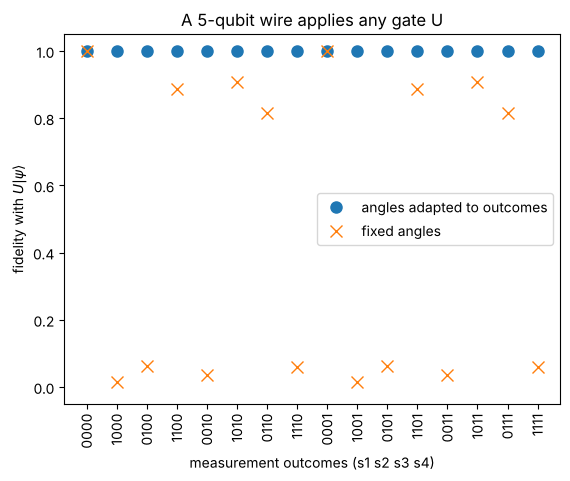

In [4]:
U = np.linalg.qr(rng.normal(size=(2, 2)) + 1j * rng.normal(size=(2, 2)))[0]  # a random single-qubit gate
angles = rotation_angles(U)
patterns = [tuple((k >> b) & 1 for b in range(4)) for k in range(16)]

for adaptive, marker in [(True, "o"), (False, "x")]:
    fids = [fidelity(run_wire(psi, angles, outcomes=o, adaptive=adaptive)[0], U @ psi) for o in patterns]
    plt.plot(range(16), fids, marker, ms=8, label="angles adapted to outcomes" if adaptive else "fixed angles")
plt.xticks(range(16), ["".join(map(str, o)) for o in patterns], rotation=90)
plt.xlabel("measurement outcomes (s1 s2 s3 s4)")
plt.ylabel(r"fidelity with $U|\psi\rangle$")
plt.ylim(-0.05, 1.05)
plt.title("A 5-qubit wire applies any gate U")
plt.legend();

With feedforward, every one of the 16 random outcome patterns gives exactly $U|\psi\rangle$. Without it, only the lucky patterns do. Adding vertical edges between wires gives two-qubit gates (lesson 4), and a single-qubit gate set plus CNOT is universal, so a large enough cluster state can run any quantum circuit.

## Where to go next

| Lesson | What you learn |
|---|---|
| [1. Graph states](01_graph_states.ipynb) | The resource state, its stabilizers and its entanglement |
| [2. Teleportation and feedforward](02_teleportation_and_feedforward.ipynb) | The basic move above, derived, and why byproducts flip later angles |
| [3. Single-qubit rotations](03_single_qubit_rotations.ipynb) | The 5-qubit wire in detail |
| [4. CNOT on a 2D patch](04_cnot_on_a_2d_patch.ipynb) | Two-qubit gates from a 2D cluster |
| [5. Universality and circuits](05_universality_and_circuits.ipynb) | A circuit-to-measurement compiler; Clifford circuits in one round |
| [6. Photonics, fusion and noise](06_photonics_fusion_and_noise.ipynb) | How photonic hardware builds cluster states, and what noise does |